# Model Comparison

Cross-architecture comparison of the regressors: accuracy-versus-model-size trade-off,
per-parameter and per-phase performance, and latent-space (UMAP) structure of the learned
representations.


In [1]:
!pip install tensorflow --quiet
!pip install scikit-learn --quiet
!pip install pandas --quiet
!pip install matplotlib --quiet
!pip install tqdm --quiet
!pip uninstall tensorflow-text -y --quiet   # evita el choque de símbolos
!pip install keras-hub==0.26.0 --quiet
print("✅ Librerías listas. REINICIA EL KERNEL antes de seguir.")

✅ Librerías listas. REINICIA EL KERNEL antes de seguir.


In [2]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import tensorflow as tf
import keras_hub                      # antes de cargar modelos
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

FONTSCALE = 1.5
FS_TITLE  = 13 * FONTSCALE
FS_LABEL  = 11 * FONTSCALE
FS_TICK   = 10 * FONTSCALE
FS_STATS  =  9 * FONTSCALE
FS_LEGEND =  9 * FONTSCALE
c_line = "#1a5276"

OUT_DIR = "/workspace/Process/Images"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs("/workspace/Process/metrics", exist_ok=True)
   
param_names = ["T", "Jex2", "Jex3", "Jex4", "Kan1", "KanS", "Hex", "KDM"]
param_labels = {
    "T": r"$T^{(0)}$", "Jex2": r"$\tilde{J}_2$", "Jex3": r"$\tilde{J}_3$",
    "Jex4": r"$\tilde{J}_4$", "Kan1": r"$\tilde{K}_{an1}$", "KanS": r"$\tilde{K}_{anS}$",
    "Hex": r"$\tilde{H}_{ex}$", "KDM": r"$\tilde{K}_{DM}$",
}
N_PARAMS = 8
identificables = ["T", "Jex2", "Kan1", "KanS", "Hex", "KDM"]

print(f"TF: {tf.__version__} | keras_hub: {keras_hub.__version__} | GPUs: {len(gpus)}")

2026-07-14 23:43:38.684770: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-14 23:43:38.757536: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-07-14 23:43:40.262381: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TF: 2.20.0 | keras_hub: 0.26.0 | GPUs: 1


In [3]:
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"
     
data = np.load(DATASET_PATH, allow_pickle=True)
X = np.copy(data['img']).astype(np.float32)
y = np.copy(data['params']).astype(np.float32)
     
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1765, random_state=SEED)

scaler = MinMaxScaler().fit(y_train)
y_true = y_test.copy()
data_range = scaler.data_max_ - scaler.data_min_

del X_train, X_val, y_val; gc.collect()
print(f"Test: {X_test.shape[0]:,} imágenes")

Test: 24,922 imágenes


In [4]:
BASE = "/workspace/Models/Inverse/ModelWeights"
       
# Comparación arquitectónica principal (propuesta resaltada)
MODELS_MAIN = {
    "ViT":              f"{BASE}/modelo_vit_baseline_estructuras.keras",
    "DenseNet":         f"{BASE}/modelo_densenet_baseline_estructuras.keras",
    "ResNet":           f"{BASE}/modelo_resnet_baseline_estructuras.keras",
    "Xception":     f"{BASE}/modelo_xception_aug_scratch_noweights_estructuras.keras",
    "CNN":        f"{BASE}/light_cnn_noweights_estructuras.keras",   # PROPUESTA
}
PROPOSED = "CNN"
    
# Par para el experimento ImageNet (mismo modelo, único cambio: preentrenamiento)
MODELS_IMAGENET = {
    "Xception-Aug (ImageNet)": f"{BASE}/modelo_xception_aug_weighted_estructuras.keras",
    "Xception-Aug (scratch)":  f"{BASE}/modelo_xception_scratch_aug_weighted_estructuras.keras",
}


 
class PhysicalAugmentation(tf.keras.layers.Layer):
    def call(self, x, training=None): return x
    def get_config(self): return super().get_config()

def load_any(path):
    try:
        return tf.keras.models.load_model(path, compile=False)
    except Exception:
        return tf.keras.models.load_model(
            path, compile=False,
            custom_objects={"PhysicalAugmentation": PhysicalAugmentation})

def predict_model(model, X_arr, batch=128):
    input_hw = model.input_shape[1]
    n_out    = model.output_shape[-1]
    ds = tf.data.Dataset.from_tensor_slices(X_arr)
    if input_hw != 39:
        ds = ds.map(lambda im: tf.image.grayscale_to_rgb(tf.image.resize(im, [input_hw, input_hw])),
                    num_parallel_calls=tf.data.AUTOTUNE)
    raw = model.predict(ds.batch(batch).prefetch(tf.data.AUTOTUNE), verbose=0)
    if n_out == 2 * N_PARAMS:
        return scaler.inverse_transform(raw[:, :N_PARAMS])
    return scaler.inverse_transform(raw)

def count_params(path):
    m = load_any(path); n = m.count_params()
    del m; gc.collect(); tf.keras.backend.clear_session()
    return n

print("✅ Registro listo. Propuesta:", PROPOSED)

✅ Registro listo. Propuesta: CNN


In [5]:
preds, n_params_model = {}, {}
for mname, mpath in MODELS_MAIN.items():
    print(f"▶ {mname}...", end=" ")
    if not os.path.exists(mpath):
        print("✗ no existe"); continue
    model = load_any(mpath)
    n_params_model[mname] = model.count_params()
    preds[mname] = predict_model(model, X_test)
    r2i = np.mean([r2_score(y_true[:, param_names.index(p)], preds[mname][:, param_names.index(p)])
                   for p in identificables])
    print(f"OK | {n_params_model[mname]:,} params | R² ident: {r2i:.4f}")
    del model; gc.collect(); tf.keras.backend.clear_session()
  
ok = list(preds.keys())
print(f"\n✅ Modelos: {ok}")

▶ ViT... 

I0000 00:00:1784072673.671826     202 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 140841 MB memory:  -> device: 0, name: NVIDIA H200, pci bus id: 0000:3a:00.0, compute capability: 9.0
2026-07-14 23:44:39.909830: I external/local_xla/xla/service/service.cc:163] XLA service 0x7182e8015fb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-07-14 23:44:39.909877: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA H200, Compute Capability 9.0
2026-07-14 23:44:40.046715: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-07-14 23:44:40.584971: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-07-14 23:44:43.817360: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spi

OK | 86,001,672 params | R² ident: 0.8907
▶ DenseNet... OK | 7,307,080 params | R² ident: 0.8799
▶ ResNet... OK | 24,123,528 params | R² ident: 0.8910
▶ Xception... 

2026-07-14 23:46:12.331599: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-14 23:46:12.449780: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-14 23:46:13.594557: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-14 23:46:13.705858: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-14 23:46:44.280660: E external/local_xla/xla/stream_

OK | 21,397,296 params | R² ident: 0.8987
▶ CNN... 

2026-07-14 23:47:05.715184: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-07-14 23:47:10.306978: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


OK | 1,244,392 params | R² ident: 0.8537

✅ Modelos: ['ViT', 'DenseNet', 'ResNet', 'Xception', 'CNN']


In [6]:
rows = []
for m in ok:
    r2_all   = np.mean([r2_score(y_true[:, i], preds[m][:, i]) for i in range(N_PARAMS)])
    r2_ident = np.mean([r2_score(y_true[:, param_names.index(p)], preds[m][:, param_names.index(p)])
                        for p in identificables])
    nmae     = np.mean([mean_absolute_error(y_true[:, i], preds[m][:, i]) / data_range[i]
                        for i in range(N_PARAMS)])
    rows.append({"Model": m, "Params": n_params_model[m],
                 "Params (M)": round(n_params_model[m] / 1e6, 2),
                 "R²_ident": round(r2_ident, 4), "R²_todos": round(r2_all, 4),
                 "nMAE": round(nmae, 4)})

df = pd.DataFrame(rows).set_index("Model").sort_values("Params")
print(df.to_string())
df.to_csv("/workspace/Process/metrics/comparison_final.csv")

best = df["R²_ident"].idxmax()
prop_r2 = df.loc[PROPOSED, "R²_ident"]
print(f"\nMejor R² ident: {best} ({df.loc[best,'R²_ident']:.4f})")
print(f"Propuesta {PROPOSED}: {prop_r2:.4f} con {df.loc[PROPOSED,'Params (M)']}M params "
      f"({df['Params'].max()/n_params_model[PROPOSED]:.0f}× más liviano que el mayor)")

            Params  Params (M)  R²_ident  R²_todos    nMAE
Model                                                     
CNN        1244392        1.24    0.8537    0.6411  0.0400
DenseNet   7307080        7.31    0.8799    0.6256  0.0418
Xception  21397296       21.40    0.8987    0.6750  0.0385
ResNet    24123528       24.12    0.8910    0.5548  0.0420
ViT       86001672       86.00    0.8907    0.5934  0.0418

Mejor R² ident: Xception (0.8987)
Propuesta CNN: 0.8537 con 1.24M params (69× más liviano que el mayor)


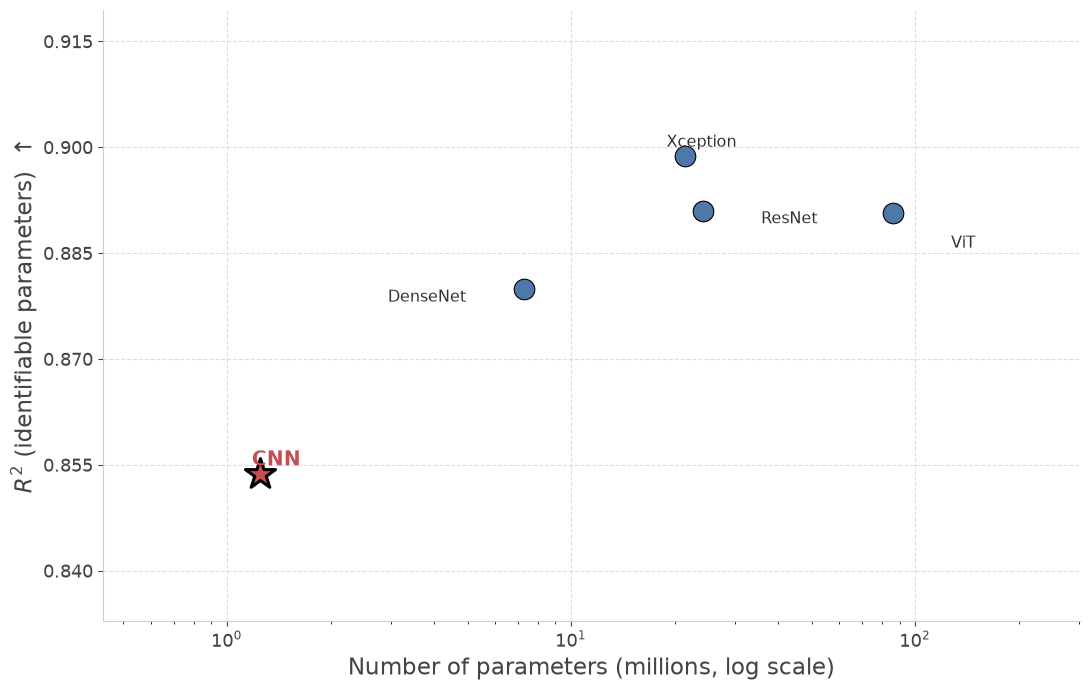

In [8]:
fig, ax = plt.subplots(figsize=(11, 7), facecolor="white")

# Offsets de etiqueta por modelo (dx, dy en puntos)
label_offsets = {
    "CNN-Aug-W":    (0,   22),
    "Xception-Aug": (42,  10),
    "ResNet":       (42,  -6),
    "DenseNet":     (-42, -6),
    "ViT":          (42,  -22),
}
label_ha = {
    "CNN-Aug-W": "center", "Xception-Aug": "left", "ResNet": "left",
    "DenseNet": "right", "ViT": "left",
}

for m in ok:
    is_prop = (m == PROPOSED)
    px = n_params_model[m] / 1e6
    py = df.loc[m, "R²_ident"]
    ax.scatter(px, py,
               s=520 if is_prop else 220,
               color="#C44E52" if is_prop else "#4e79a7",
               edgecolor="black", linewidth=2.2 if is_prop else 0.8,
               zorder=5 if is_prop else 3, marker="*" if is_prop else "o")
    dx, dy = label_offsets.get(m, (12, 10))
    ax.annotate(m, (px, py),
                textcoords="offset points", xytext=(dx, dy),
                fontsize=FS_STATS * (1.05 if is_prop else 0.85),
                fontweight="bold" if is_prop else "normal",
                color="#C44E52" if is_prop else "#333333",
                ha=label_ha.get(m, "center"), va="center", zorder=6)

ax.set_xscale("log")

# ── Eje Y ajustado al rango REAL de los datos (sin espacio muerto) ──
y_vals = [df.loc[m, "R²_ident"] for m in ok]
y_lo, y_hi = min(y_vals), max(y_vals)
margin = (y_hi - y_lo) * 0.35 + 0.005      # margen proporcional al spread
ax.set_ylim(y_lo - margin, min(y_hi + margin, 1.0))
ax.yaxis.set_major_locator(plt.MaxNLocator(6))

ax.set_xlabel("Number of parameters (millions, log scale)", fontsize=FS_LABEL, color="#444444")
ax.set_ylabel(r"$R^2$ (identifiable parameters)  ↑", fontsize=FS_LABEL, color="#444444")
ax.tick_params(labelsize=FS_TICK * 0.85, colors="#444444")
ax.grid(linestyle="--", alpha=0.4, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.spines["left"].set_color("#cccccc"); ax.spines["bottom"].set_color("#cccccc")

# Aire horizontal para las etiquetas laterales
xmin = min(n_params_model.values()) / 1e6
xmax = max(n_params_model.values()) / 1e6
ax.set_xlim(xmin * 0.35, xmax * 3.5)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/accuracy_vs_size.pdf", bbox_inches="tight", facecolor="white")
plt.show()

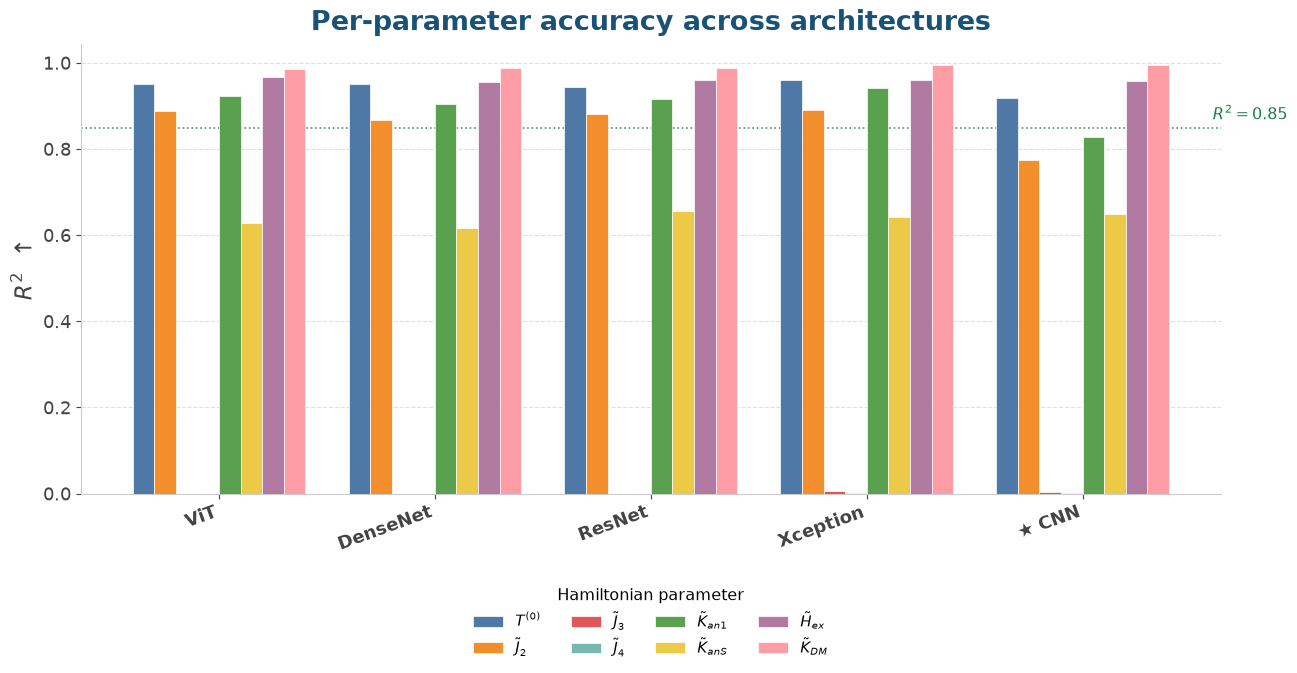

In [9]:
var_colors = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2",
              "#59a14f", "#edc948", "#b07aa1", "#ff9da7"]
x = np.arange(len(ok)); bar_w = 0.10

fig, ax = plt.subplots(figsize=(13, 7), facecolor="white")
for v_i, name in enumerate(param_names):
    offset = (v_i - N_PARAMS / 2 + 0.5) * bar_w
    vals = [max(r2_score(y_true[:, param_names.index(name)], preds[m][:, param_names.index(name)]), 0)
            for m in ok]
    ax.bar(x + offset, vals, width=bar_w, color=var_colors[v_i],
           edgecolor="white", linewidth=0.5, zorder=3, label=param_labels[name])

ax.axhline(0.85, color="#1a7a4a", linewidth=1.2, linestyle=":", alpha=0.8)
ax.text(len(ok) - 0.05, 0.86, r"$R^2=0.85$", fontsize=FS_STATS * 0.85,
        color="#1a7a4a", va="bottom", ha="right")
ax.set_xticks(x)
labels = [f"★ {m}" if m == PROPOSED else m for m in ok]
ax.set_xticklabels(labels, fontsize=FS_TICK * 0.85, rotation=20, ha="right", fontweight="bold")
ax.set_ylabel(r"$R^2$  ↑", fontsize=FS_LABEL, color="#444444")
ax.set_title("Per-parameter accuracy across architectures",
             fontsize=FS_TITLE, fontweight="bold", color=c_line, pad=10)
ax.tick_params(labelsize=FS_TICK * 0.85, colors="#444444")
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.set_ylim(bottom=0)
ax.legend(fontsize=FS_LEGEND * 0.8, frameon=False, ncol=4,
          loc="upper center", bbox_to_anchor=(0.5, -0.18),
          title="Hamiltonian parameter", title_fontsize=FS_LEGEND * 0.85)
ax.spines[["top", "right"]].set_visible(False)
ax.spines["left"].set_color("#cccccc"); ax.spines["bottom"].set_color("#cccccc")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/r2_by_parameter_final.pdf", bbox_inches="tight", facecolor="white")
plt.show()

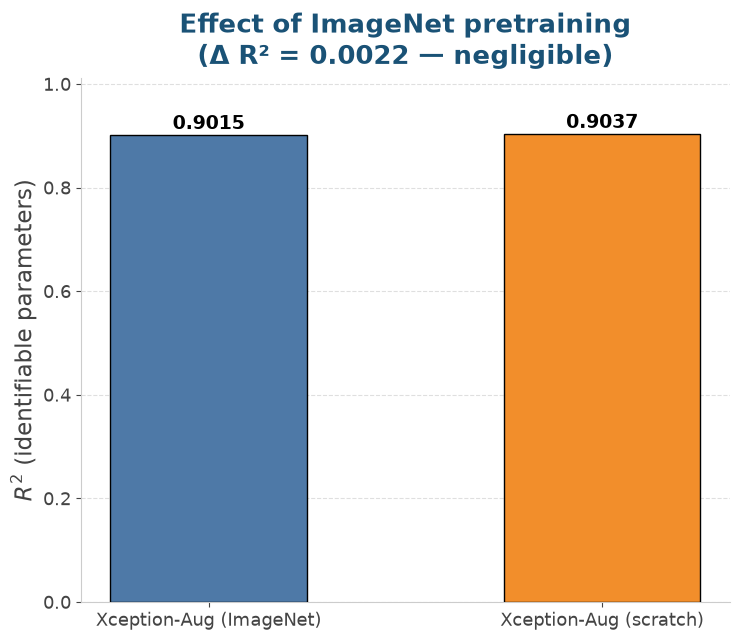

ImageNet: 0.9015  |  Scratch: 0.9037  |  Δ = 0.0022
→ El preentrenamiento no aporta a la precisión en este dominio.


In [10]:
imnet_r2 = {}
for mname, mpath in MODELS_IMAGENET.items():
    model = load_any(mpath)
    yp = predict_model(model, X_test)
    imnet_r2[mname] = np.mean([r2_score(y_true[:, param_names.index(p)], yp[:, param_names.index(p)])
                               for p in identificables])
    del model; gc.collect(); tf.keras.backend.clear_session()

fig, ax = plt.subplots(figsize=(7.5, 6.5), facecolor="white")
names = list(imnet_r2.keys())
vals  = [imnet_r2[n] for n in names]
bars = ax.bar(names, vals, width=0.5, color=["#4e79a7", "#f28e2b"],
              edgecolor="black", linewidth=1.0, zorder=3)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.003, f"{v:.4f}",
            ha="center", va="bottom", fontsize=FS_STATS, fontweight="bold")

diff = abs(vals[0] - vals[1])
ax.set_ylabel(r"$R^2$ (identifiable parameters)", fontsize=FS_LABEL, color="#444444")
ax.set_title(f"Effect of ImageNet pretraining\n(Δ R² = {diff:.4f} — negligible)",
             fontsize=FS_TITLE * 0.95, fontweight="bold", color=c_line, pad=10)
ax.tick_params(labelsize=FS_TICK * 0.85, colors="#444444")
ax.set_ylim(0, max(vals) * 1.12)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.spines["left"].set_color("#cccccc"); ax.spines["bottom"].set_color("#cccccc")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/imagenet_effect.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print(f"ImageNet: {vals[0]:.4f}  |  Scratch: {vals[1]:.4f}  |  Δ = {diff:.4f}")
print("→ El preentrenamiento no aporta a la precisión en este dominio.")